# 01 · Red-teaming data exploration

What data does the Review 2 pipeline run on, and how do the datasets differ?

This notebook looks at four **simulated red-team campaigns** that ship with the project (no download needed) and, if you have fetched them, two **real red-teaming datasets** (Anthropic red-team attempts and JailbreakBench attack artifacts).

Every simulated row is one turn of a conversation between an attacker and a target model. A hidden *compliance state* (refusal, partial compliance or full violation) drives the three probabilities the judge reports for that turn. The hidden state is the "answer key"; the clustering methods never see it.

Run order: this notebook, then `02_review2_walkthrough.ipynb`, then the interactive UI (`streamlit run app.py`).

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
if os.path.basename(os.getcwd()) == "notebooks":   # run from the repo root so relative data paths work
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from src.analysis import scenarios, trace, external_data as ext
from src.analysis.unsupervised import SCORE_COLUMNS, conversation_features, adjusted_rand
get_ipython().run_line_magic('matplotlib', 'inline')   # the repo's analysis modules force the Agg backend; switch back so plots show here
from src.analysis.utils import COMPLIANCE_STATES, load_transcript_rows

STATE_COLORS = ["#2F6FED", "#F2A20C", "#E5484D"]   # refusal, partial, full violation
PALETTE = ["#2F6FED", "#F2A20C", "#E5484D", "#16A34A", "#7C3AED", "#0EA5A4"]


## 1. Load the four simulated campaigns

In [2]:
def load_baseline():
    try:
        return load_transcript_rows().dropna(subset=["true_compliance_state"])
    except FileNotFoundError:
        from data.generate_synthetic_campaign import generate
        import json
        os.makedirs("data/transcripts", exist_ok=True)
        with open("data/transcripts/synthetic_campaign_pbl.jsonl", "w") as f:
            for r in generate():
                f.write(json.dumps(r) + "\n")
        return load_transcript_rows().dropna(subset=["true_compliance_state"])

CAMPAIGNS = {"baseline": load_baseline()}
for key in scenarios.SCENARIOS:
    CAMPAIGNS[key] = scenarios.simulate(key)

for key, df in CAMPAIGNS.items():
    print(f"{key:11s} {len(df):5d} turns, {df.conversation_id.nunique():3d} conversations")
print()
for key, p in scenarios.SCENARIOS.items():
    print(f"{key}: {p['about']}\n")

baseline      978 turns, 220 conversations
noisy        1259 turns, 300 conversations
stealthy     1762 turns, 220 conversations
persistent   2200 turns, 220 conversations

noisy: A less reliable judge: the three score distributions overlap heavily, so refusal, partial and full-violation turns are hard to tell apart. Same dynamics as the baseline campaign.

stealthy: A careful attacker that escalates slowly: conversations run up to 12 turns, most turns are refusals or partial compliance, and full violation is rare and late.

persistent: No early stop: the campaign keeps talking after a success, and a broken target tends to stay broken (92% chance to stay in full violation). Here the sequence structure is real, not an artefact of stopping.



## 2. Side by side: size, length and how often the attack succeeds

In [3]:
rows = []
for key, df in CAMPAIGNS.items():
    last = df.sort_values("timestep_in_conversation").groupby("conversation_id")["true_compliance_state"].last()
    share = df["true_compliance_state"].value_counts(normalize=True)
    rows.append({
        "campaign": key, "turns": len(df), "conversations": df.conversation_id.nunique(),
        "mean turns / conv": round(len(df) / df.conversation_id.nunique(), 2),
        "refusal": round(share.get("refusal", 0), 3), "partial": round(share.get("partial_compliance", 0), 3), "full violation": round(share.get("full_violation", 0), 3),
        "conversations ending in full violation": round((last == "full_violation").mean(), 3),
    })
pd.DataFrame(rows).set_index("campaign")

,turns,conversations,mean turns / conv,refusal,partial,full violation,conversations ending in full violation
campaign,,,,,,,
baseline,978,220,4.45,0.535,0.318,0.147,0.623
noisy,1259,300,4.20,0.458,0.357,0.184,0.483
stealthy,1762,220,8.01,0.640,0.285,0.075,0.591
persistent,2200,220,10.00,0.225,0.239,0.537,0.732


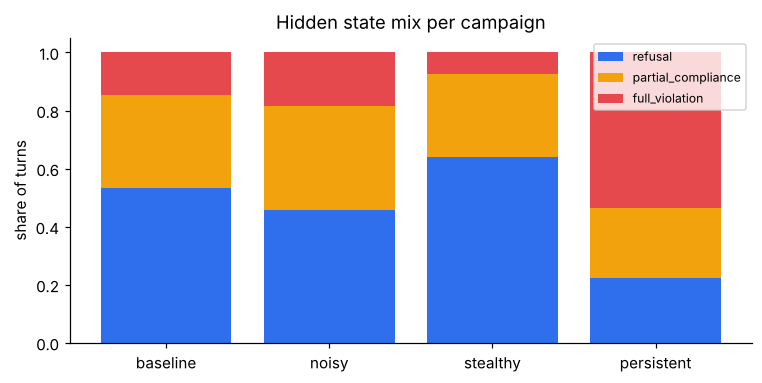

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
keys = list(CAMPAIGNS)
bottom = np.zeros(len(keys))
for j, state in enumerate(COMPLIANCE_STATES):
    vals = np.array([(CAMPAIGNS[k]["true_compliance_state"] == state).mean() for k in keys])
    ax.bar(keys, vals, bottom=bottom, color=STATE_COLORS[j], label=state)
    bottom += vals
ax.set_ylabel("share of turns"); ax.set_title("Hidden state mix per campaign"); ax.legend(loc="upper right", fontsize=8)
plt.show()

## 3. Is the judge's signal clean or blurry?

For each true state, the histogram shows what the judge's **p(full violation)** looked like. In a clean campaign the three states barely overlap. In the noisy campaign they overlap heavily, which is exactly what makes unsupervised recovery hard.

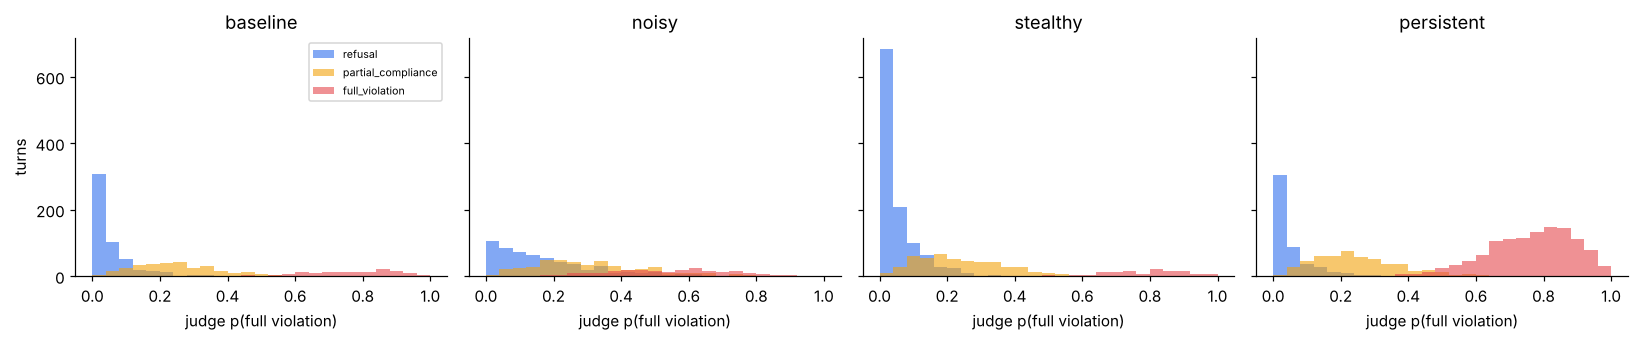

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, (key, df) in zip(axes, CAMPAIGNS.items()):
    for j, state in enumerate(COMPLIANCE_STATES):
        ax.hist(df.loc[df.true_compliance_state == state, "judge_full_violation"], bins=25, range=(0, 1), alpha=.6, color=STATE_COLORS[j], label=state)
    ax.set_title(key); ax.set_xlabel("judge p(full violation)")
axes[0].set_ylabel("turns"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 4. How conversations move between states (empirical transition matrices)

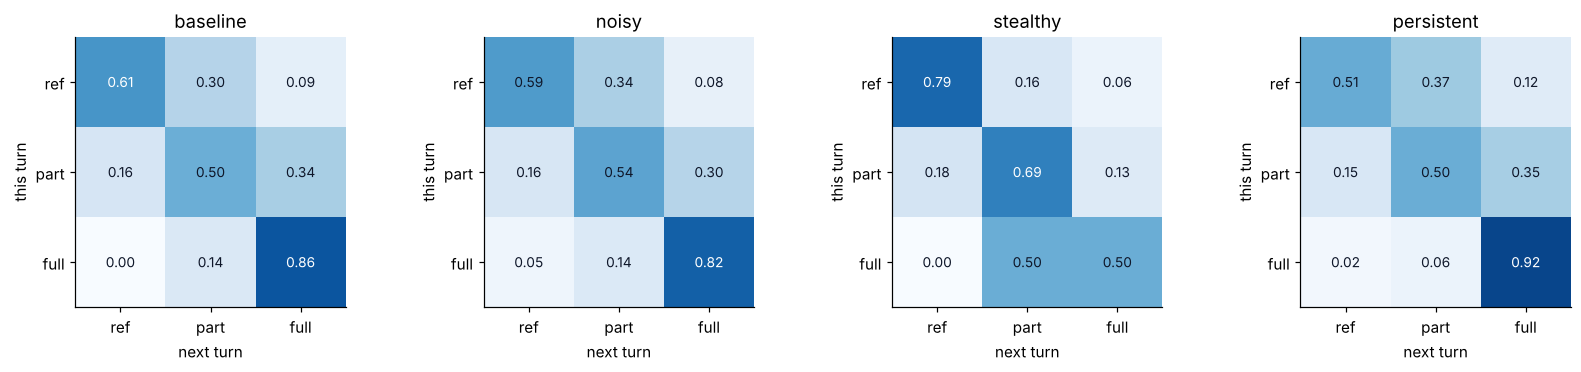

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (key, df) in zip(axes, CAMPAIGNS.items()):
    d = df.sort_values(["conversation_id", "timestep_in_conversation"])
    nxt = d.groupby("conversation_id")["true_compliance_state"].shift(-1)
    pairs = pd.crosstab(d["true_compliance_state"], nxt).reindex(index=COMPLIANCE_STATES, columns=COMPLIANCE_STATES).fillna(0)
    P = pairs.div(pairs.sum(axis=1).replace(0, 1), axis=0)
    ax.imshow(P.values, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{P.values[i, j]:.2f}", ha="center", va="center", color="#0F172A" if P.values[i, j] < .6 else "white", fontsize=9)
    ax.set_xticks(range(3)); ax.set_xticklabels(["ref", "part", "full"]); ax.set_yticks(range(3)); ax.set_yticklabels(["ref", "part", "full"])
    ax.set_title(key); ax.set_xlabel("next turn"); ax.set_ylabel("this turn")
plt.tight_layout(); plt.show()

In campaigns that stop at the first success (baseline, noisy, stealthy) few turns follow a full violation, so its row is estimated from very few turns. In *persistent*, conversations continue, so the staying probability is a real property.

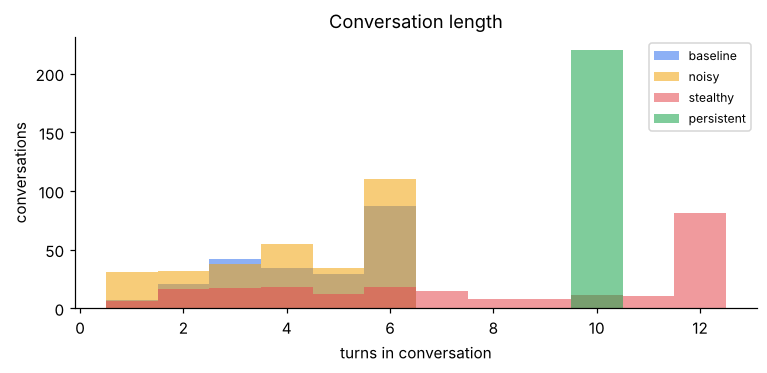

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for j, (key, df) in enumerate(CAMPAIGNS.items()):
    lens = df.groupby("conversation_id").size()
    ax.hist(lens, bins=np.arange(0.5, 13.5), alpha=.55, color=PALETTE[j], label=key)
ax.set_xlabel("turns in conversation"); ax.set_ylabel("conversations"); ax.set_title("Conversation length"); ax.legend(fontsize=8)
plt.show()

## 5. How separable is each campaign? A quick difficulty ranking

Two numbers per campaign, both computed on the three standardized judge scores:

* **label silhouette**: how well the *true* states form tight, separated groups (needs the answer key, so it describes the data, not a method)
* **K-means matched accuracy**: what plain K-means recovers *without* labels (the full comparison is in notebook 02)

In [8]:
from src.analysis.unsupervised import silhouette, kmeans
ranking = []
for key, df in CAMPAIGNS.items():
    X = df[SCORE_COLUMNS].values
    Xs, _, _ = trace.zscore(X)
    p = trace.pca_trace(Xs)
    Z = (Xs - p["mean"]) @ p["eigvecs"][:, :2]
    y = df["true_compliance_state"].map(COMPLIANCE_STATES.index).values
    labels = kmeans(Z, 3)[0]
    ranking.append({"campaign": key, "label silhouette": round(silhouette(Z, y), 3), "K-means matched accuracy": round(trace.score(Z, labels, y)["accuracy"], 3), "K-means ARI": round(adjusted_rand(y, labels), 3)})
pd.DataFrame(ranking).set_index("campaign")

,label silhouette,K-means matched accuracy,K-means ARI
campaign,,,
baseline,0.660,0.969,0.924
noisy,0.127,0.641,0.235
stealthy,0.668,0.971,0.923
persistent,0.635,0.955,0.870


## 6. Real red-teaming datasets (optional download)

Two public datasets are wired into the UI. They use their **own numeric scores and tags**; no judge model is run and no conversation text is shown.

| Dataset | Rows | Label | Features |
|---|---|---|---|
| Anthropic red-team attempts (`Anthropic/hh-rlhf`, `red-team-attempts`) | ~39k conversations | human success rating 0 to 4 | harmlessness scores, turns, lengths, target size and type, tags |
| JailbreakBench artifacts (`JailbreakBench/artifacts`) | PAIR / GCG attacks on real targets | `jailbroken` yes/no | query and token counts, lengths, refusal-phrase flag, attack method |

Fetch them once (needs internet):

```bash
pip install datasets
python -m src.analysis.external_data redteam
python -m src.analysis.external_data jbb
```

In [9]:
REAL = {}
for name, loader in [("Anthropic red-team attempts", ext.load_redteam), ("JailbreakBench artifacts", ext.load_jbb)]:
    try:
        X, y, classes, about = loader()
        REAL[name] = (X, y, classes)
        print(f"OK  {name}: {X.shape[0]} rows x {X.shape[1]} features, classes = {classes}")
    except ext.DatasetUnavailable as e:
        print(f"--  {name}: not available here ({e})")
if not REAL:
    print("\nNothing downloaded yet: the simulated campaigns above are all this notebook needs.")

--  Anthropic red-team attempts: not available here (Anthropic red-team-attempts is not downloaded yet.)
--  JailbreakBench artifacts: not available here (JailbreakBench artifacts are not downloaded yet.)

Nothing downloaded yet: the simulated campaigns above are all this notebook needs.


In [10]:
for name, (X, y, classes) in REAL.items():
    print(f"\n=== {name} ===")
    print(pd.Series(y).map(lambda i: classes[i]).value_counts().to_frame("rows").assign(share=lambda d: (d.rows / d.rows.sum()).round(3)))
    # how strongly does each feature relate to the label? (absolute correlation, for orientation only)
    corr = X.apply(lambda c: abs(np.corrcoef(c, y)[0, 1]) if c.std() > 0 else 0.0).sort_values(ascending=False)
    display(corr.head(8).round(3).to_frame("|correlation with label|"))
    fig, ax = plt.subplots(figsize=(6, 2.6)); corr.head(8)[::-1].plot.barh(ax=ax, color="#0D9488"); ax.set_title(f"{name}: top feature/label correlations"); plt.show()

## Takeaways to carry into notebook 02

* The four campaigns differ in **how clean the judge is**, **how fast the attacker escalates**, **how long conversations run** and **whether success ends the conversation**. Those are the knobs real campaigns vary on.
* All four are simulated: the hidden state generates the scores, so separation is built in. Treat the real datasets as the honest test.
* Next: `02_review2_walkthrough.ipynb` runs PCA, K-means, GMM-EM, hierarchical clustering and the HMM on any of these, cell by cell.